In [1]:
# Regularization can be easily implemented using Keras Dense's
# kernel_regularizer and bias_regularizer, but to better
# understand how regularization works, we implement it by
# creating a regularized loss function.
import numpy as np
import tensorflow as tf
from sklearn.datasets import make_blobs
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.keras import optimizers
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import pickle

In [2]:
# Generate a dataset
x, y = make_blobs(n_samples=300, n_features=2,
                  centers=[[0., 0.], [0.5, 0.1]],
                  cluster_std=0.25, center_box=(-1., 1.))
y = y.reshape(-1, 1).astype('float32')
x_train, x_test, y_train, y_test = train_test_split(x, y)
with open('data/blobs.pkl', 'wb') as f:
    pickle.dump([x_train, x_test, y_train, y_test], f)

In [3]:
with open('data/blobs.pkl', 'rb') as f:
    x_train, x_test, y_train, y_test = pickle.load(f)

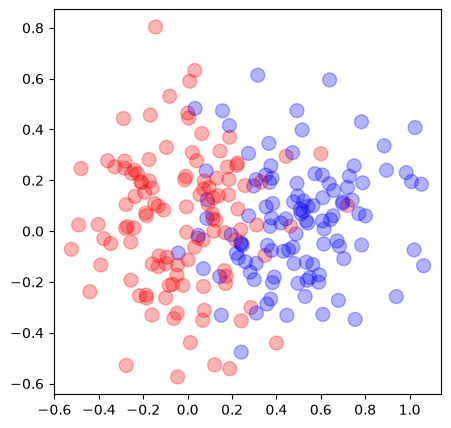

In [4]:
# Visually see the distribution of the data points
plt.figure(figsize=(5, 5))
color = [['red', 'blue'][int(a)] for a in y_train.reshape(-1,)]
plt.scatter(x_train[:, 0], x_train[:, 1], s=100, c=color, alpha=0.3)
plt.show()

In [5]:
# Create an ANN model.
n_input = x_train.shape[1]   # number of input neurons
n_output = 1                 # number of output neurons
n_hidden = 32                # number of hidden neurons
R = 0.001                    # Regularization constant
e = 1e-6                     # Small value to avoid log(0)
adam = optimizers.Adam(learning_rate=0.001)

# The data is simple, but we intentionally added many hidden
# layers to the model to demonstrate the effect of regularization.
x_input = Input(batch_shape=(None, n_input))
h = Dense(n_hidden, activation='relu')(x_input)

# 4 more hidden layers
for i in range(4):
    h = Dense(n_hidden, activation='relu')(h)

y_output = Dense(n_output, activation='sigmoid')(h)
model = Model(x_input, y_output)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,353 (17.00 KB)

 Trainable params: 4,353 (17.00 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# 0: no regularization, 1: L1, 2: L2, 12: L1 & L2
params = model.trainable_variables
r_list = [1, -1, 2, 2, 12, 2, 1, 2, -1, 2]

In [7]:
# Custom loss function: regularized loss
class reg_loss(tf.keras.losses.Loss):
    def __init__(self, reg_lambda, params, r_list, **kwargs):
        super().__init__(**kwargs)
        self.R = reg_lambda
        self.params = params
        self.r_list = r_list

    def call(self, y, y_pred):
        bce = -tf.reduce_mean(
            y * tf.math.log(y_pred + e) + \
            (1. - y) * tf.math.log(1. - y_pred + e))

        reg_terms = 0
        for i, p in zip(self.r_list, self.params):
            if i == 1:  # L1 regularization
                reg_terms += tf.reduce_sum(tf.math.abs(p))

            if i == 2:  # L2 regularization
                reg_terms += tf.reduce_sum(tf.math.square(p))

            if i == 12:  # L1 & L2 regularization
                reg_terms += tf.reduce_sum(tf.math.abs(p))
                reg_terms += tf.reduce_sum(tf.math.square(p))

        return bce + self.R * reg_terms

model.compile(loss=reg_loss(R, params, r_list), optimizer = adam)
f = model.fit(x_train, y_train,
              validation_data=[x_test, y_test],
              epochs=200, batch_size=20)

Epoch 1/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 1.0621 - val_loss: 1.0287
Epoch 2/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.9915 - val_loss: 0.9553
Epoch 3/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.8976 - val_loss: 0.8577
Epoch 4/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.7787 - val_loss: 0.7539
Epoch 5/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6728 - val_loss: 0.6944
Epoch 6/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6190 - val_loss: 0.6777
Epoch 7/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5984 - val_loss: 0.6646
Epoch 8/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5829 - val_loss: 0.6498
Epoch 9/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5680 - val_loss: 0.6359
Epoch 10/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5543 - val_loss: 0.6234
Epoch 11/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.5420 - val_loss: 0.6128
Epoch 12/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.

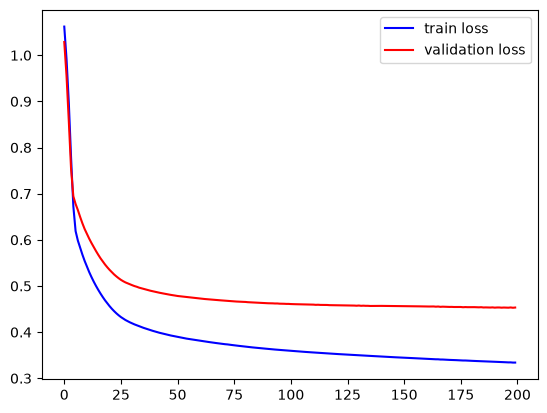

In [8]:
# Visually see the loss history
plt.plot(f.history['loss'], c='blue', label='train loss')
plt.plot(f.history['val_loss'], c='red', label='validation loss')
plt.legend()
plt.show()

In [9]:
# Check the accuracy of the test data
y_pred = (model.predict(x_test) > 0.5) * 1
acc = (y_pred == y_test).mean()
print("\nAccuracy of the test data = {:.2f}".format(acc))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 

Accuracy of the test data = 0.83
